In [73]:
#Import libs
import numpy
import matplotlib.pyplot as plt
from pathlib import Path
import torchvision.datasets as datasets

data_dir = Path("../data")
print(data_dir.resolve())

/home/minhnguyen0207/Projects/Number-Recognition/data


In [74]:
#Get MNIST datasets
train_data = datasets.MNIST(
    root = data_dir,
    train = True,
    download = True
)

test_data = datasets.MNIST(
    root = data_dir,
    train = False,
    download = True
)

In [77]:
X_train = train_data.data.numpy()
y_train = train_data.targets.numpy()

X_test = test_data.data.numpy()
y_test = test_data.targets.numpy()

In [ ]:
#Checking training properties
print(f"X_train's shape is: {X_train.shape}")
print(f"X_train's dtype is: {X_train.dtype}")
print(f"Min is: {X_train.min()}")
print(f"Max is: {X_train.max()}")

#Predict the center pixels:
'''
The center's distribution will depend on numbers, for example 0 might have blank center and for the others might have denser pixels
'''
center_slice = X_train[:,12:16, 12:16]
mean_center = center_slice.mean()
print(f"Average pixels in the center is: {mean_center}")
print(f"Ink ratio is: {(center_slice > 0).mean()}")

#Therefore a single picture can not depict the whole dataset

X_train's shape is: (60000, 28, 28)
X_train's dtype is: uint8
Min is: 0
Max is: 255
Average pixels in the center is: 109.714296875
Ink ratio is: 0.5969020833333334


array([[190, 253,  70,   0],
       [ 35, 241, 225, 160],
       [  0,  81, 240, 253],
       [  0,   0,  45, 186]], dtype=uint8)

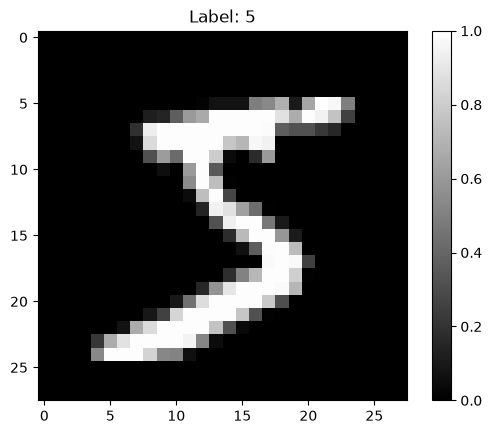

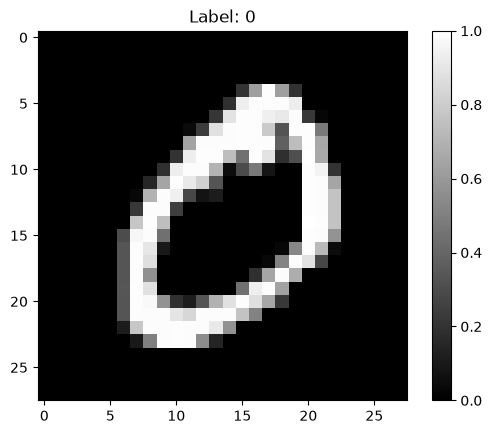

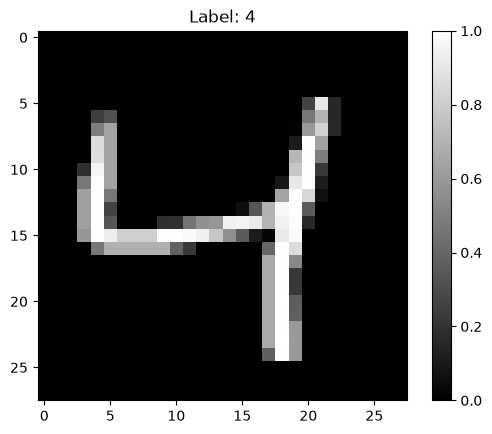

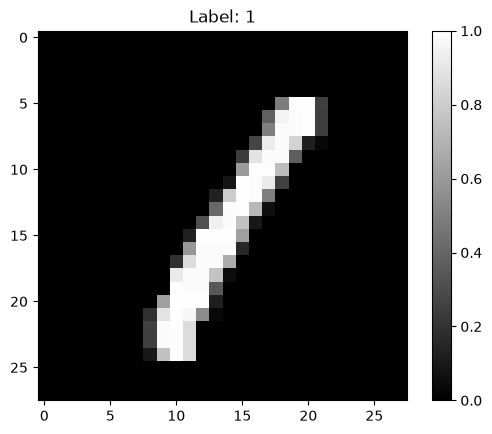

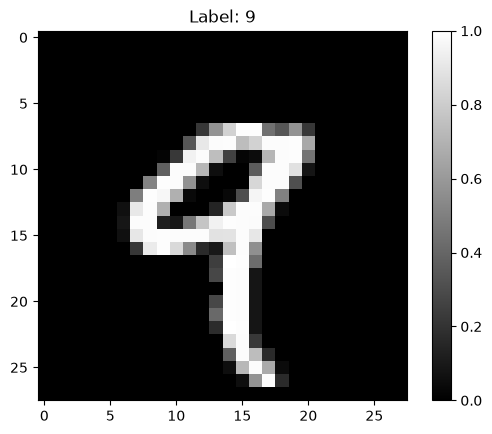

In [69]:
#Showing a picture
for i in range(5):
    plt.imshow((X_train[i] / numpy.float32(255)), cmap="gray",vmin=0.0,vmax=1.0)
    plt.title(f"Label: {y_train[i]}")
    plt.colorbar()
    plt.show()


In [ ]:
#Analysing y_train (targets)

#Using numpy.bincount()
num_bincount = numpy.bincount(y_train,minlength=10)
print(num_bincount)

#Using numpy.unique(a, return_counts=True)
num_value, num_count= numpy.unique(y_train, return_counts=True)
print(num_value,num_count)

#Using Loop
loop_count = []
for d in range(0,10):
    loop_count.append((y_train == d).sum())
print(loop_count)

#Check if numpy.bincount same as loop_count
assert numpy.array_equal(num_bincount, loop_count)

#Check if num_value is enough digits
assert numpy.array_equal(num_value,[0,1,2,3,4,5,6,7,8,9])

#Check if num_count is equal to both num_bincount and loop_count
assert numpy.array_equal(num_count, num_bincount) and numpy.array_equal(num_count, loop_count)

[5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]
[0 1 2 3 4 5 6 7 8 9] [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]
[np.int64(5923), np.int64(6742), np.int64(5958), np.int64(6131), np.int64(5842), np.int64(5421), np.int64(5918), np.int64(6265), np.int64(5851), np.int64(5949)]


y_train's shape is: (60000,)
y_train.dtype is: int64
Min value is: 0
Max value is: 9


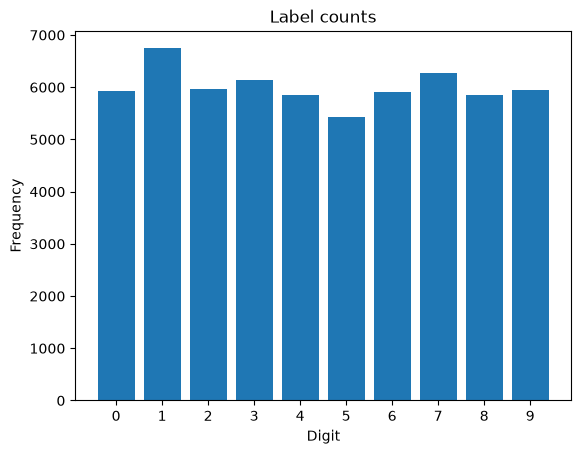

In [ ]:
#Analysing y_train
print(f"y_train's shape is: {y_train.shape}")
print(f"y_train.dtype is: {y_train.dtype}")
print(f"Min value is: {y_train.min()}")
print(f"Max value is: {y_train.max()}")

#Showing y_train bar chart
plt.bar(range(0,10), num_bincount)
plt.xticks(range(10))
plt.title("Label counts")
plt.xlabel("Digit")
plt.ylabel("Frequency")
plt.show()

y_test's shape is: (10000,)
y_test's dtype is: int64
Min value is: 0
Max value is: 9
values count is: [ 980 1135 1032 1010  982  892  958 1028  974 1009]
[0.2  1.35 0.32 0.1  0.18 1.08 0.42 0.28 0.26 0.09]


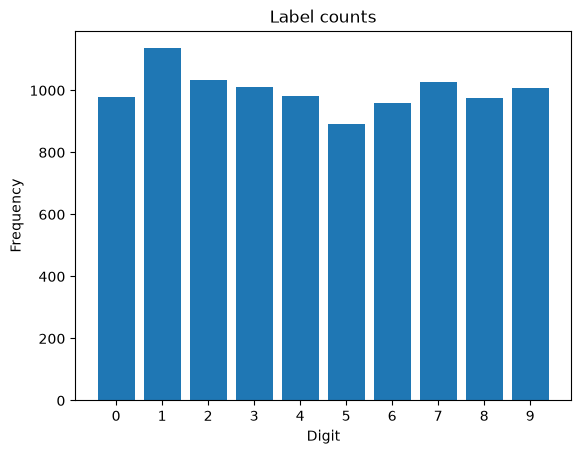

In [ ]:
#Analysing y_test
print(f"y_test's shape is: {y_test.shape}")
print(f"y_test's dtype is: {y_test.dtype}")
print(f"Min value is: {y_test.min()}")
print(f"Max value is: {y_test.max()}")
print(f"values count is: {numpy.bincount(y_test, minlength=10)}")
print(abs(numpy.bincount(y_test, minlength=10) / 100 -10))

#Showing y_test bar chart
plt.bar(range(0,10), numpy.bincount(y_test, minlength=10))
plt.xticks(range(10))
plt.title("Label counts")
plt.xlabel("Digit")
plt.ylabel("Frequency")
plt.show()


In [83]:
# 1. Is the dataset balanced? Compute the ratio of the max class to the min class.
min_quantity = num_bincount.min()
max_quantity = num_bincount.max()

min_val = num_value[num_count.argmin()]
max_val = num_value[num_count.argmax()]

ratio = round(max_quantity / min_quantity, 2)

print(f"Most and least numbers: {max_val} with {max_quantity} and {min_val} with {min_quantity}")
print(ratio)

pct_per_value = abs((num_bincount / len(y_train)) * 100 - 10)
print(pct_per_value)

Most and least numbers: 1 with 6742 and 5 with 5421
1.24
[0.12833333 1.23666667 0.07       0.21833333 0.26333333 0.965
 0.13666667 0.44166667 0.24833333 0.085     ]
